# Will my farm get drier?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/will_my_farm_get_drier.ipynb)

**The question:** *"Will the fields I farm get less rain and longer dry spells,
and how bad could a dry year get?"*

Crops don't care about the average year; a farm is made or broken by its **dry
years**. We answer three times, each with a better data source, using the same
open toolkit, [crc-sdk](https://github.com/RiskThinking/crc-sdk):

| | Data | What it can tell you |
|---|---|---|
| **A** | JRC European Drought Observatory soil moisture | How dry the soil got in past years (Europe only) |
| **B** | **CRC Open**: free, ready-made climate curves | Rain, dry days and dry spells in 2025–2080 under a high-emissions future (SSP5-8.5; [other futures on request](mailto:sales@riskthinking.ai)) |
| **C** | **CDT**, Riskthinking.AI's Climate Digital Twin (enterprise) | The same against a historical baseline, for every emissions future |

Run it on Colab with **Runtime → Run all**; no account needed for A and B.
Change `FARM` in the setup cell to try another place (A covers Europe only).

## Setup

In [1]:
#@title Install packages (Colab) and choose a farm
import importlib.util
import os
import subprocess
import sys

IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        "crc-sdk[netcdf,geometry]>=0.11.1,<1", "plotly>=6,<7", "velo-sdk",
    ])

# Wheat country in Castilla y León, Spain. Any farm works for B and C; A needs Europe.
FARM = {"name": "Valladolid wheat farm, Spain", "latitude": 41.65, "longitude": -4.72}

# Small, quick runs for continuous integration; the same code runs either way.
CI = os.environ.get("CRC_DOCS_CI") == "1"
EDO_YEARS = (2005, 2024) if CI else ("all_complete",)   # about 30 seconds per year; needs 20+ years
EARLY, LATE = (2025, 2030, 2035), (2070, 2075, 2080)

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow as pa
import pyarrow.parquet as pq

from crc_sdk.workflows import EDODroughtPolicy, HazardDataset, curve_parameters_from_row

# Interactive charts when you run it; saved images so GitHub can show them too.
STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"

DATA = Path("data") / "farm"
DATA.mkdir(parents=True, exist_ok=True)

INK, EARLY_COLOR, LATE_COLOR = "#52514e", "#f5b08f", "#9c3a12"
CDT_COLORS = {"historic": "#52514e", "ssp126": "#2a78d6", "ssp245": "#1baf7a", "ssp585": "#eb6834"}
FONT = dict(family="Inter, Helvetica, Arial, sans-serif", size=14)
RP_TICKS = [1, 2, 5, 10, 20, 50, 100]
rp_grid = np.geomspace(1.2, 100, 200)


def wet_side(distribution, rp):
    """Value reached or exceeded once every `rp` years (upper tail)."""
    return np.asarray(distribution.quantiles((1 - 1 / np.asarray(rp, dtype=float)).tolist()), dtype=float)


def dry_side(distribution, rp):
    """Value at or below which a year falls once every `rp` years (lower tail)."""
    return np.asarray(distribution.quantiles((1 / np.asarray(rp, dtype=float)).tolist()), dtype=float)


def layout(fig, title, **kwargs):
    fig.update_layout(title=dict(text=title, x=0.01), font=FONT, height=430,
                      margin=dict(l=70, r=30, t=70, b=60), **kwargs)
    return fig


def log_rp_axis(title="Return period (years, log scale)", **kwargs):
    return dict(type="log", title=title, tickvals=RP_TICKS, **kwargs)

## A. Ask the drought observatory

The EU's [European Drought Observatory](https://drought.emergency.copernicus.eu/)
publishes a **Soil Moisture Index** for every 5 km of Europe since 1995 (CC BY 4.0).
It runs from **0**, soil so dry that plants can no longer draw water (the wilting
point), to **1**, soil holding as much water as it can. crc-sdk keeps each year's
**driest moment** and fits a curve through those yearly minima (the lower tail,
because here *low* is bad).

In [3]:
edo_plan = (
    HazardDataset.smi(version="latest")
    .for_area((FARM["longitude"] - 0.1, FARM["latitude"] - 0.1,
               FARM["longitude"] + 0.1, FARM["latitude"] + 0.1))
    .years(*EDO_YEARS)
    .cache(DATA / "edo", mode="reuse")
    .canonicalize(policy=EDODroughtPolicy.curated(h3_resolution=6))
)
(DATA / "smi.parquet").unlink(missing_ok=True)   # this plan won't overwrite; refitting from the cache is quick
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    edo_plan.materialize(DATA / "smi.parquet")

from shapely import wkb
from shapely.geometry import Point

farm_point = Point(FARM["longitude"], FARM["latitude"])
edo_rows = [row for row in pq.read_table(DATA / "smi.parquet").to_pylist() if row["curve_kind"] != "no_data"]
edo_row = min(edo_rows, key=lambda row: wkb.loads(row["source_geometry"]).distance(farm_point)
              if row["source_geometry"] else 0)
soil = curve_parameters_from_row(edo_row).to_distribution()
print(f"{len(edo_rows)} soil-moisture curves around the farm; using the nearest")

283 soil-moisture curves around the farm; using the nearest


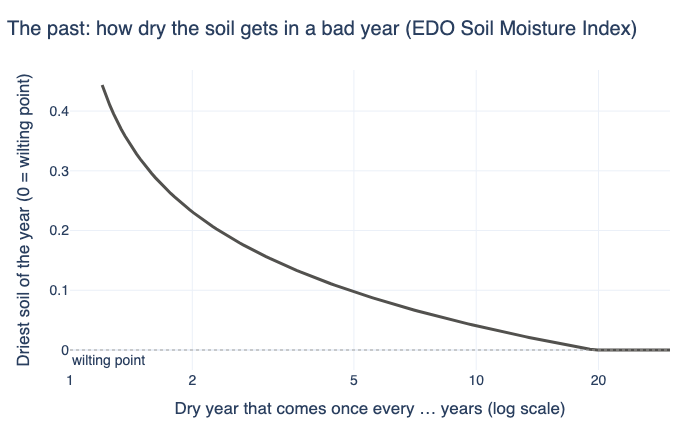

About once every 20 years, the soil dries all the way to the wilting point.


,a dry year that comes once every … years,driest soil (index)
0,2,0.23
1,5,0.10
2,10,0.04
3,20,-0.00


In [4]:
soil_grid = np.geomspace(1.2, 30, 150)   # about 30 years of records: stay within reach
soil_levels = np.maximum(dry_side(soil, soil_grid), 0)   # the index cannot go below the wilting point
fig = go.Figure()
fig.add_trace(go.Scatter(x=soil_grid, y=soil_levels, mode="lines", line=dict(color=INK, width=3),
                         name="Driest soil of the year", hovertemplate="1-in-%{x:.0f} dry year: %{y:.2f}<extra></extra>"))
fig.add_hline(y=0, line=dict(color="#a3a29e", width=1, dash="dot"), annotation_text="wilting point",
              annotation_position="bottom left")
layout(fig, "The past: how dry the soil gets in a bad year (EDO Soil Moisture Index)",
       xaxis=log_rp_axis(range=[0, np.log10(30)], title="Dry year that comes once every … years (log scale)"),
       yaxis=dict(title="Driest soil of the year (0 = wilting point)"), showlegend=False)
fig.show()
if soil_levels.min() <= 0:
    wilting_rp = soil_grid[np.argmax(soil_levels <= 0)]
    print(f"About once every {wilting_rp:.0f} years, the soil dries all the way to the wilting point.")
table = pd.DataFrame({"a dry year that comes once every … years": [2, 5, 10, 20]})
table["driest soil (index)"] = dry_side(soil, table.iloc[:, 0]).round(2)
table

Read it the other way round from the rain and heat notebooks: the curve goes
**down** to the right, because rarer years are **drier**.

**What A tells us, and what it can't:**

- ✅ Measures what crops actually feel: water in the soil.
- ❌ **Only the past** (about 30 years), and **only Europe**.
- ❌ **No breakdown**: it can't say whether dry years come from less rain, longer
  dry spells or more heat drying the soil.

## B. Ask CRC Open

[CRC Open](https://github.com/RiskThinking/crc-sdk/blob/main/docs/sources/crc-open.md)
has ready-made curves for 63 hazards worldwide, 2025–2100
([CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/)). For a farm,
three tell the dry-weather story:

- **annual rainfall** (`prcptot`): how much falls in a year;
- **dry days** (`dry_days`): how many days a year get almost no rain;
- **longest dry spell** (`max_consecutive_dry_days`): the longest run of dry days.

We compare 2025–2035 with 2070–2080, each averaged over three horizons.

This public release covers one high-emissions future, SSP5-8.5. Lower-emissions
futures are available too: [contact sales](mailto:sales@riskthinking.ai).

In [5]:
def crc_open_curves(hazard):
    plan = (
        HazardDataset.crc_open()
        .for_area((FARM["longitude"] - 0.05, FARM["latitude"] - 0.05,
                   FARM["longitude"] + 0.05, FARM["latitude"] + 0.05))
        .hazards([hazard])
        .horizons(list(EARLY + LATE))
        .cache(DATA / "crc-open", mode="reuse")
    )
    farm = pa.table({"asset_id": [FARM["name"]], "longitude": [FARM["longitude"]], "latitude": [FARM["latitude"]]})
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        plan.for_assets(farm).return_periods([2]).write_parquet(DATA / f"farm_{hazard}.parquet")
        plan.materialize(DATA / f"{hazard}.parquet")
    cell = pq.read_table(DATA / f"farm_{hazard}.parquet").column("cell_index")[0].as_py()
    rows = [row for row in pq.read_table(DATA / f"{hazard}.parquet").to_pylist()
            if row["cell_index"] == cell and row["curve_kind"] != "no_data"]
    return {row["horizon"]: curve_parameters_from_row(row).to_distribution() for row in rows}


def window(curves, horizons, side, rp):
    return np.mean([side(curves[h], rp) for h in horizons if h in curves], axis=0)


rain = crc_open_curves("prcptot")
dry_days = crc_open_curves("dry_days")
spell = crc_open_curves("max_consecutive_dry_days")

summary = pd.DataFrame([
    ("Annual rain, typical year (mm)", window(rain, EARLY, dry_side, [2])[0], window(rain, LATE, dry_side, [2])[0]),
    ("Annual rain, 1-in-10 dry year (mm)", window(rain, EARLY, dry_side, [10])[0], window(rain, LATE, dry_side, [10])[0]),
    ("Dry days, 1-in-10 year", window(dry_days, EARLY, wet_side, [10])[0], window(dry_days, LATE, wet_side, [10])[0]),
    ("Longest dry spell, 1-in-10 year (days)", window(spell, EARLY, wet_side, [10])[0], window(spell, LATE, wet_side, [10])[0]),
], columns=["measure", "2025–2035", "2070–2080"])
summary["change"] = (100 * (summary["2070–2080"] / summary["2025–2035"] - 1)).map("{:+.0f}%".format)
summary.round(0)

,measure,2025–2035,2070–2080,change
0,"Annual rain, typical year (mm)",417.0,363.0,-13%
1,"Annual rain, 1-in-10 dry year (mm)",324.0,274.0,-15%
2,"Dry days, 1-in-10 year",256.0,275.0,+7%
3,"Longest dry spell, 1-in-10 year (days)",69.0,91.0,+32%


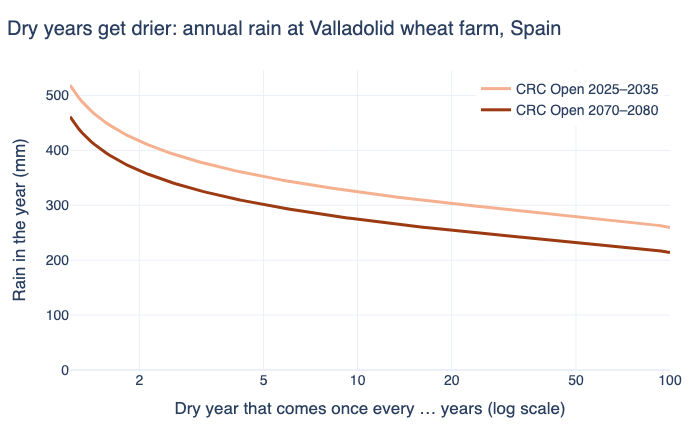

In [6]:
early_rain, late_rain = window(rain, EARLY, dry_side, rp_grid), window(rain, LATE, dry_side, rp_grid)
fig = go.Figure()
fig.add_trace(go.Scatter(x=rp_grid, y=early_rain, mode="lines", line=dict(color=EARLY_COLOR, width=3),
                         name="CRC Open 2025–2035", hovertemplate="1-in-%{x:.0f} dry year: %{y:.0f} mm<extra></extra>"))
fig.add_trace(go.Scatter(x=rp_grid, y=late_rain, mode="lines", line=dict(color=LATE_COLOR, width=3),
                         name="CRC Open 2070–2080", hovertemplate="1-in-%{x:.0f} dry year: %{y:.0f} mm<extra></extra>"))
trend = "Dry years get drier" if late_rain[-1] < early_rain[-1] else "Dry years get wetter"
layout(fig, f"{trend}: annual rain at {FARM['name']}",
       xaxis=log_rp_axis(title="Dry year that comes once every … years (log scale)"), yaxis=dict(title="Rain in the year (mm)", rangemode="tozero"),
       legend=dict(x=0.99, y=0.99, xanchor="right"))
fig.show()

> 💡 **Key idea: a shift of the whole curve hits the dry years hardest.** Each
> point on these curves is a kind of year: on the left a normal year, on the
> right a once-a-decade or once-a-century drought. Lose a similar *share* of
> rain everywhere and the dry years cross thresholds that matter, such as the
> minimum rain a rain-fed crop needs, far more often.

### The answer, in one picture

Take today's **1-in-10-year longest dry spell** and ask how often a spell that
long comes around later in the century.

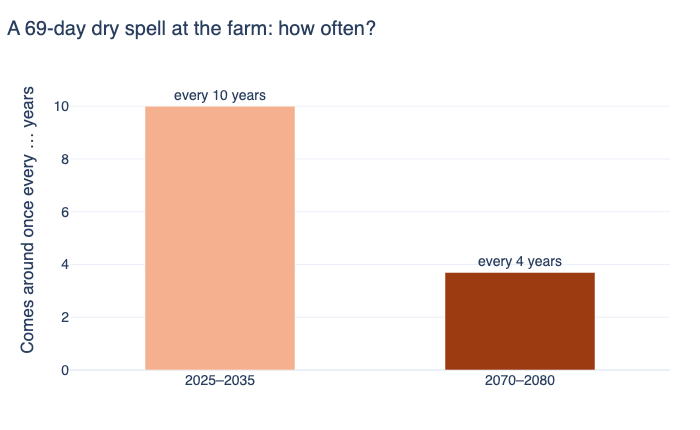

In [7]:
threshold = float(window(spell, EARLY, wet_side, [10])[0])
late_levels = window(spell, LATE, wet_side, rp_grid)
late_rp = float(np.exp(np.interp(threshold, late_levels, np.log(rp_grid))))

fig = go.Figure(go.Bar(
    x=["2025–2035", "2070–2080"], y=[10, late_rp], marker_color=[EARLY_COLOR, LATE_COLOR], width=0.5,
    text=["every 10 years", f"every {late_rp:.0f} years" if late_rp >= 1.95 else "almost every year"],
    textposition="outside", cliponaxis=False, hovertemplate="%{x}: once every %{y:.1f} years<extra></extra>",
))
layout(fig, f"A {threshold:.0f}-day dry spell at the farm: how often?",
       yaxis=dict(title="Comes around once every … years", rangemode="tozero"), showlegend=False)
fig.show()

**What B adds over A:** the future, worldwide, and *why* the farm gets drier
(less rain, more dry days, longer dry spells), all in one format.

**What B leaves out:** one emissions pathway (SSP5-8.5) and no historical
baseline from the same models. Need other pathways or a baseline for planning,
lending or disclosure? [Contact our sales team](mailto:sales@riskthinking.ai).

## C. Ask CDT

**CDT** (Climate Digital Twin) is Riskthinking.AI's enterprise service. It adds a
**historical baseline** (around 2010) and **every emissions pathway**. Here:
annual rain in a typical year and in a 1-in-10 dry year, historical vs 2070–2090
(averaged) under three futures.

The saved results below come from a CDT run: a small table and one chart. To run
it yourself you need an API key; [start a CDT Express trial](https://velo.riskthinking.ai/cdt-express)
to get one. In Colab, store it as a secret named `RISKTHINKING_API_KEY`. Without a
key the cells explain how to get one and skip.

Prefer chatting to coding? Connect the [CDT Express MCP server](https://github.com/RiskThinking/cdt-express-mcp)
to Claude or ChatGPT and ask: *"How much less rain will Valladolid get in a dry year by 2080?"*

In [8]:
api_key = os.environ.get("RISKTHINKING_API_KEY")
if api_key is None and IN_COLAB:
    from google.colab import userdata
    try:
        api_key = userdata.get("RISKTHINKING_API_KEY")
    except Exception:
        api_key = None

cdt = None
if api_key:
    from velo_sdk.api import APIClient

    client = APIClient(api_key=api_key)
    requests = [("historic", 2010)] + [(p, h) for p in ("ssp126", "ssp245", "ssp585") for h in (2070, 2080, 2090)]
    records = []
    for pathway, horizon in requests:
        response = client.get("/v4/climate/metrics/exposure", params={
            "latitude": FARM["latitude"], "longitude": FARM["longitude"], "risk_factor": "prcptot",
            "pathway": pathway, "horizon": str(horizon), "percentiles": "10,50",
        })
        for result in response["results"]:
            if result["index_name"] == "prcptot":
                percentiles = result["exposure_percentiles"]
                records.append({"pathway": pathway, "typical year (mm)": float(percentiles["50"]),
                                "1-in-10 dry year (mm)": float(percentiles["10"])})
    cdt = pd.DataFrame(records).groupby("pathway").mean().reindex([p for p in CDT_COLORS])
    display(cdt.round(0))
else:
    print("No RISKTHINKING_API_KEY found, so section C is skipped.")
    print("Start a trial at https://velo.riskthinking.ai/cdt-express, or contact sales@riskthinking.ai.")

,typical year (mm),1-in-10 dry year (mm)
pathway,,
historic,438.0,347.0
ssp126,424.0,300.0
ssp245,399.0,284.0
ssp585,362.0,248.0


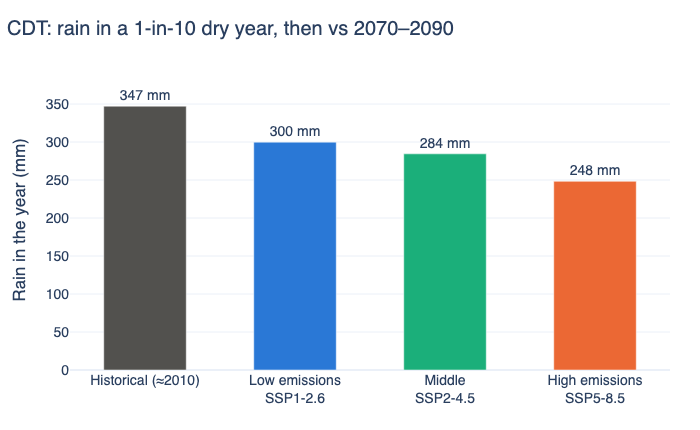

A 1-in-10 dry year brings 347 mm in the historical baseline; by 2070–2090 300 mm (SSP1-2.6) to 248 mm (SSP5-8.5), -28%.


In [9]:
if cdt is not None:
    labels = {"historic": "Historical (≈2010)", "ssp126": "Low emissions<br>SSP1-2.6",
              "ssp245": "Middle<br>SSP2-4.5", "ssp585": "High emissions<br>SSP5-8.5"}
    dry = cdt["1-in-10 dry year (mm)"].dropna()
    fig = go.Figure(go.Bar(
        x=[labels[p] for p in dry.index], y=dry, marker_color=[CDT_COLORS[p] for p in dry.index], width=0.55,
        text=[f"{v:.0f} mm" for v in dry], textposition="outside", cliponaxis=False,
        hovertemplate="%{x}: %{y:.0f} mm<extra></extra>",
    ))
    layout(fig, "CDT: rain in a 1-in-10 dry year, then vs 2070–2090",
           yaxis=dict(title="Rain in the year (mm)", rangemode="tozero"), showlegend=False)
    fig.show()
    print(f"A 1-in-10 dry year brings {dry['historic']:.0f} mm in the historical baseline; "
          f"by 2070–2090 {dry['ssp126']:.0f} mm (SSP1-2.6) to {dry['ssp585']:.0f} mm (SSP5-8.5), "
          f"{100 * (dry['ssp585'] / dry['historic'] - 1):+.0f}%.")

**What C adds over B:**

- **A matching historical baseline**, so "drier than before" compares like with like.
- **Every pathway**, so you can show how much a lower-emissions world spares the farm.
- **Financial impact and portfolios**, for lenders, insurers and food companies
  with many farms or suppliers.

## Recap

| | A. EDO soil moisture | B. CRC Open | C. CDT |
|---|---|---|---|
| Past | ✅ measured (since 1995) | ➖ not included | ✅ modelled baseline |
| Future | ❌ | ✅ 2025–2100 | ✅ 2025–2100 |
| Where | Europe | Worldwide | Worldwide |
| What | Soil moisture | Rain, dry days, dry spells and 60 more | The same, plus financial impact |
| Emissions pathways | ❌ | SSP5-8.5 ([others on request](mailto:sales@riskthinking.ai)) | All, plus warming levels |
| Cost | Free | Free (non-commercial) | [Trial](https://velo.riskthinking.ai/cdt-express), then licence |

**Next steps:** change `FARM` and run again; run the same analysis headlessly with
[`pipelines/will_my_farm_get_drier.py`](https://github.com/RiskThinking/crc-docs/blob/main/pipelines/will_my_farm_get_drier.py);
or ask an AI assistant with the [farm-drought skill](https://github.com/RiskThinking/crc-docs/blob/main/.agents/skills/will-my-farm-get-drier/SKILL.md).

*Data: JRC European Drought Observatory (CC BY 4.0); CRC Open by Riskthinking.AI
(CC BY-NC 4.0); CDT by Riskthinking.AI (licensed).*